# Sentiment Analysis — DeBERTa-v3-base + rotating balanced sampling (v2)
Run top to bottom. Needs `pool/val/test_processed{DATA_TAG}.csv` from `clean_preprocess_v3.ipynb`.
After training, run `Ensemble_Postprocess.ipynb` to blend models and tune the decision rule.

**What changed vs v1**
- Backbone: `microsoft/deberta-v3-base` (needs `pip install sentencepiece protobuf`); other models are one `MODEL_NAME` change away
- Input ablation via `DATA_TAG` (e.g. Summary | Review only) and head+tail truncation for long reviews
- Loss: CE-dominant with label smoothing (accuracy-oriented), ordinal/regression terms kept small
- Layer-wise LR decay + EMA weights; early stopping on accuracy; 5 epochs

<div dir="rtl">

## گزارش بخش ۳ — مدل تحلیل احساس (خلاصه برای اعضای گروه)

- **هدف:** پیش‌بینی ستون `overall` (عدد ۱ تا ۵) از متن نظر. ورودی مدل: `reviewText` (مبنای اصلی) به‌همراه `summary` (خلاصه‌ی نظر، اطلاعات اضافه‌ی مجاز).
- **معیار ارزیابی:** micro‑F1. در طبقه‌بندی تک‌برچسبی چندکلاسه micro‑F1 دقیقاً برابر accuracy است؛ برای همین early stopping روی `acc` انجام می‌شود و در بخش ۹ مقدار micro‑F1 هم صریحاً چاپ می‌شود.
- **مدل پیش‌آموخته + fine‑tune:** از مدل `microsoft/deberta-v3-base` استفاده شده است. این مدل از قبل روی حجم زیادی متن انگلیسی آموزش دیده است؛ ما **همه‌ی لایه‌ها به‌علاوه‌ی لایه‌ی طبقه‌بند** را روی داده‌ی نظرات آمازون (حوزه‌ی مسئله) fine‑tune می‌کنیم، یعنی فقط استفاده‌ی آماده از مدل نیست.
- **استفاده از بخشی از داده:** در هر epoch فقط ۳۰٬۰۰۰ نمونه از هر کلاس (۱۵۰٬۰۰۰ ردیف) از pool خوانده می‌شود و در epoch بعد زیرمجموعه‌ی جدیدی انتخاب می‌شود (Rotating Balanced Sampling)؛ به این ترتیب منابع سخت‌افزاری کنترل می‌شود ولی داده‌ی بیشتری دیده می‌شود.
- **Validation جدا:** ۶٬۰۰۰ نمونه از هر کلاس (۳۰٬۰۰۰ ردیف) کنار گذاشته شده و هرگز در آموزش استفاده نمی‌شود. متن‌های تکراری بین val و pool هم از pool حذف شده‌اند تا نشت (leakage) نداشته باشیم.
- **فایل ارسالی:** در بخش ۱۱ فایل `q2_submission.csv` (یک ستون `predicted`، بدون index، به ترتیب ردیف‌های تست) ساخته می‌شود.

</div>

<div dir="rtl">

## معماری و روش آموزش (برای تسلط اعضای گروه بر الگوریتم)

**جریان داده:** متن → tokenizer (با برش head+tail برای متن‌های بلند، حداکثر ۲۵۶ توکن) → Transformer encoder (self‑attention، برای هر توکن یک بردار وابسته به کل جمله می‌سازد) → **mean pooling** روی توکن‌های غیر‑padding → LayerNorm → Dropout(۰٫۱) → Linear(hidden→۵) → softmax. پیش‌بینی نهایی `argmax + 1` است.

**مدل:** DeBERTa‑v3‑base: ۱۲ لایه، حدود ۱۸۴ میلیون پارامتر؛ از disentangled attention (بردار محتوا و موقعیت جدا) و pre‑training از نوع replaced‑token‑detection استفاده می‌کند و معمولاً در طبقه‌بندی متن از RoBERTa‑base دقیق‌تر است. نیازمند `pip install sentencepiece protobuf`.

**تابع هزینه:** ۰٫۷·CrossEntropy (با label smoothing برابر ۰٫۱) + ۰٫۱۵·ordinal BCE (احتمال تجمعی «امتیاز بزرگ‌تر از k») + ۰٫۱۵·SmoothL1 روی امتیاز مورد انتظار. دلیل: امتیازها ترتیب دارند (اشتباه ۴ به‌جای ۵ کم‌هزینه‌تر از ۱ به‌جای ۵ است) ولی چون معیار نهایی accuracy است، سهم اصلی با CrossEntropy است.

**ترفندهای آموزش:**
- **Layer‑wise LR decay:** لایه‌های پایین (دانش عمومی زبان) با نرخ یادگیری کمتر و لایه‌های بالا سریع‌تر آپدیت می‌شوند تا دانش پیش‌آموخته خراب نشود.
- **EMA وزن‌ها (۰٫۹۹۹):** میانگین متحرک وزن‌ها، پیش‌بینی پایدارتر؛ ارزیابی و ذخیره با همین وزن‌ها انجام می‌شود.
- **AdamW + cosine schedule + warmup ۶٪**، gradient clipping، mixed precision و gradient accumulation (batch مؤثر = ۳۲).
- **Early stopping** روی accuracy اعتبارسنجی (patience = ۲) و ذخیره‌ی بهترین checkpoint.

</div>

<div dir="rtl">

## پیش‌پردازش و دلیل هر انتخاب

پیش‌پردازش در `clean_preprocess_v3.ipynb` انجام می‌شود و خروجی آن (`pool/val/test_processed*.csv`) اینجا خوانده می‌شود.

**کارهایی که انجام شده است**
- **decode کردن HTML entity، حذف تگ‌های HTML و URL، یکدست‌کردن فاصله‌ها:** این‌ها هیچ اطلاعات احساسی ندارند و فقط از بودجه‌ی ۲۵۶ توکنی هدر می‌دهند.
- **ساخت ورودی `Summary: … | Review: …`:** خلاصه‌ی نظر یک جمع‌بندی کوتاه و مستقیم از رضایت کاربر است و با امتیاز همبستگی بالایی دارد؛ برچسب‌های `Summary:`/`Review:` مرز بخش‌ها را به مدل نشان می‌دهند. خلاصه به ۴۰ کلمه محدود می‌شود.
- **حذف `brand` و `title` از ورودی پیش‌فرض:** این دو بیشتر محصول را معرفی می‌کنند تا نظر کاربر را، و خطر یادگرفتن «امتیاز معمول هر محصول» به‌جای احساس متن وجود دارد. این انتخاب با ablation (جدول آزمایش‌ها در انتهای نوتبوک) بررسی می‌شود.
- **برش head+tail (۶۰٪ ابتدا، ۴۰٪ انتها):** در نظرهای بلند معمولاً جمع‌بندی و امتیاز ضمنی در انتهای متن است؛ برش ساده‌ی ابتدایی آن را دور می‌ریزد.
- **حذف متن‌های تکراری و نشت:** یک نظر مشابه اغلب زیر چند ASIN تکرار شده؛ نمونه‌های pool که متن‌شان در val هم هست حذف می‌شوند تا دقت validation خوشبینانه نشود.
- **متعادل‌سازی کلاس‌ها (val و نمونه‌گیری هر epoch):** کلاس ۵ در pool سهم بسیار بیشتری دارد؛ بدون تعادل مدل به پیش‌بینی کلاس غالب متمایل می‌شود.

**کارهایی که عمداً انجام نشده است**
- **حذف stop word:** فهرست‌های استاندارد شامل کلماتی مثل `not`، `no`، `never`، `but`، `very`، `too`، `without` هستند (مثلاً در scikit‑learn همه‌ی این‌ها هست) که دقیقاً جهت یا شدت احساس را تعیین می‌کنند: «not good» بدون `not` می‌شود «good». علاوه بر این، مدل Transformer از ترتیب و کلمات ربط در بافت جمله استفاده می‌کند و روی متن طبیعی pre‑train شده؛ متن بدون stop word با توزیع pre‑training نمی‌خواند. شاهد عددی: سلول پیوست انتهای نوتبوک (TF‑IDF با/بدون stop word).
- **lowercase و حذف علائم نگارشی:** `!!!` و حروف بزرگ (AWFUL) نشانه‌ی شدت احساس‌اند و به تفکیک ۱ از ۲ و ۴ از ۵ کمک می‌کنند. tokenizer این مدل حساس به حروف بزرگ و کوچک است و lowercase کردن ورودی با pre‑training هم‌خوان نیست.
- **stemming / lemmatization:** tokenizer زیرکلمه‌ای (subword) خودش ریخت‌شناسی را مدیریت می‌کند و stemming فقط باعث ناهم‌خوانی با واژگان مدل می‌شود.

</div>

## 1. Imports & config

In [1]:
import os, gc, math, re, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoConfig, AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, mean_absolute_error, cohen_kappa_score)

warnings.filterwarnings("ignore")

# ===================== Config =====================
MODEL_NAME = "microsoft/deberta-v3-base"
#   (heavier options if you ever get a bigger GPU: "microsoft/deberta-v3-base/large", "roberta-large";
#    DeBERTa-v3 tokenizer needs:  pip install sentencepiece)
DATA_TAG = "_summary_review"     # must equal TAG printed by clean_preprocess_v3 ("" = old Brand|Title|Summary|Review)
NUM_CLASSES = 5
MAX_LEN = 256
USE_HEAD_TAIL = True             # long reviews: keep the first part AND the ending (verdicts are usually at the end)
HEAD_FRAC = 0.6                  # share of the token budget taken from the start of the text

IS_LARGE = "large" in MODEL_NAME.lower()

# --- Rotating balanced sampling ---
PER_CLASS_PER_EPOCH = 30_000
EPOCHS = 5

# --- Batch / speed ---
TRAIN_BATCH_SIZE = 8
GRAD_ACCUM_STEPS = 4             # effective batch = 32
EVAL_BATCH_SIZE = 32
USE_GRAD_CKPT = IS_LARGE         # saves VRAM for *-large models (slower)

# --- Full fine-tuning (default) or LoRA ---
USE_LORA = False
LORA_R, LORA_ALPHA, LORA_DROPOUT = 32, 64, 0.05
BACKBONE_LR = 1e-4 if USE_LORA else (2e-5 if IS_LARGE else 3e-5)
HEAD_LR = 2e-4 if USE_LORA else 1e-4
USE_LLRD = True                  # layer-wise LR decay (full fine-tuning only)
LLRD_DECAY = 0.95 if IS_LARGE else 0.9
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
MAX_GRAD_NORM = 1.0

# --- Loss: weights for (CE, ordinal BCE, SmoothL1 on expected rating) ---
LOSS_WEIGHTS = (0.7, 0.15, 0.15)
LABEL_SMOOTHING = 0.1

# --- EMA of weights (evaluated + saved instead of the raw weights) ---
USE_EMA = True
EMA_DECAY = 0.999

# --- Early stopping ---
EARLY_STOP_METRIC = "acc"        # "acc" | "macro_f1" | "qwk"
PATIENCE = 2
SEED = 42

OUTPUT_DIR = Path("outputs_" + MODEL_NAME.split("/")[-1] + DATA_TAG)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = OUTPUT_DIR / "best_model.pt"

def seed_everything(seed=42):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
use_scaler = torch.cuda.is_available() and (not use_bf16)
print("Model:", MODEL_NAME, "| Device:", device, "| AMP dtype:", amp_dtype, "| Output:", OUTPUT_DIR)

W1102 13:21:31.128000 27220 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Model: microsoft/deberta-v3-base | Device: cuda | AMP dtype: torch.bfloat16 | Output: outputs_deberta-v3-base_summary_review


## 2. Load data

In [2]:
def load_split(path, with_label=True):
    cols = ["model_input", "overall"] if with_label else ["model_input"]
    df = pd.read_csv(path, usecols=cols)
    df["model_input"] = df["model_input"].fillna("").astype(str)
    if with_label:
        df["overall"] = df["overall"].astype(int)
    return df

pool_df = load_split(f"pool_processed{DATA_TAG}.csv")
val_df = load_split(f"val_processed{DATA_TAG}.csv")
test_df = load_split(f"test_processed{DATA_TAG}.csv", with_label=False)

print("Pool per class:\n", pool_df["overall"].value_counts().sort_index())
print("Val per class:\n", val_df["overall"].value_counts().sort_index())
print("Test rows:", len(test_df))
print("Example input:", pool_df["model_input"].iloc[0][:200])

Pool per class:
 overall
1     73754
2     48827
3     72368
4    145285
5    438310
Name: count, dtype: int64
Val per class:
 overall
1    6000
2    6000
3    6000
4    6000
5    6000
Name: count, dtype: int64
Test rows: 20000
Example input: Summary: Cannot Learn | Review: I have an older URC-WR7 remote and thought this would be an upgrade (and because TWC stuck me with it), but this one fails where the other one didn't. The old remote co


## 3. Rotating balanced sampler

In [3]:
class RotatingBalancedSampler:
    """Each call to next_epoch() returns a class-balanced set of row positions.
    Big classes advance through their own shuffled queue, so rows used in one epoch
    are not used again until the whole class has been seen (then it reshuffles).
    Small classes (pool <= k) are used completely every epoch."""

    def __init__(self, labels, per_class, seed=42):
        self.rng = np.random.default_rng(seed)
        labels = np.asarray(labels)
        self.classes = sorted(np.unique(labels).tolist())
        self.class_idx = {c: np.where(labels == c)[0] for c in self.classes}
        self.k = int(min(per_class, min(len(v) for v in self.class_idx.values())))
        self.queue = {c: self.rng.permutation(v) for c, v in self.class_idx.items()}
        self.pos = {c: 0 for c in self.classes}
        self.passes = {c: 0 for c in self.classes}
        self.seen = np.zeros(len(labels), dtype=bool)

    def next_epoch(self):
        chosen = []
        for c in self.classes:
            q, p = self.queue[c], self.pos[c]
            if p + self.k <= len(q):
                take = q[p:p + self.k]
                self.pos[c] = p + self.k
            else:  # queue exhausted: use leftovers, reshuffle, continue
                rest = q[p:]
                fresh = self.rng.permutation(self.class_idx[c])
                fresh = fresh[~np.isin(fresh, rest)]
                need = self.k - len(rest)
                take = np.concatenate([rest, fresh[:need]])
                self.queue[c], self.pos[c] = fresh, need
                self.passes[c] += 1
            chosen.append(take)
        idx = np.concatenate(chosen)
        self.rng.shuffle(idx)
        self.seen[idx] = True
        return idx

    def coverage(self):
        return {c: float(self.seen[self.class_idx[c]].mean()) for c in self.classes}


def length_grouped_batches(lengths, batch_size, rng, mega=50):
    """Batches of similar length (less padding -> faster), then shuffled."""
    lengths = np.asarray(lengths)
    order = rng.permutation(len(lengths))
    batches = []
    for i in range(0, len(order), batch_size * mega):
        chunk = order[i:i + batch_size * mega]
        chunk = chunk[np.argsort(lengths[chunk])]
        batches += [chunk[j:j + batch_size].tolist() for j in range(0, len(chunk), batch_size)]
    perm = rng.permutation(len(batches))
    return [batches[i] for i in perm]


sampler = RotatingBalancedSampler(pool_df["overall"].values, PER_CLASS_PER_EPOCH, seed=SEED)
rows_per_epoch = sampler.k * len(sampler.classes)
print(f"Per-class rows per epoch: {sampler.k:,} -> {rows_per_epoch:,} rows/epoch")
for c in sampler.classes:
    print(f"  class {c}: pool={len(sampler.class_idx[c]):,}  (~{len(sampler.class_idx[c]) / sampler.k:.1f} epochs to see all of it)")


Per-class rows per epoch: 30,000 -> 150,000 rows/epoch
  class 1: pool=73,754  (~2.5 epochs to see all of it)
  class 2: pool=48,827  (~1.6 epochs to see all of it)
  class 3: pool=72,368  (~2.4 epochs to see all of it)
  class 4: pool=145,285  (~4.8 epochs to see all of it)
  class 5: pool=438,310  (~14.6 epochs to see all of it)


## 4. Tokenizer, dataset, loaders

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.model_max_length = 10**6        # we truncate ourselves; silences length warnings

# Special tokens are added by hand (works on every transformers version): <s> ... </s>  /  [CLS] ... [SEP]
CLS_ID = tokenizer.cls_token_id if tokenizer.cls_token_id is not None else tokenizer.bos_token_id
SEP_ID = tokenizer.sep_token_id if tokenizer.sep_token_id is not None else tokenizer.eos_token_id
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
BUDGET = MAX_LEN - 2

class TextDataset(Dataset):
    def __init__(self, texts, labels=None):
        self.texts = list(texts)
        self.labels = None if labels is None else list(labels)
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        return (self.texts[i], -1 if self.labels is None else int(self.labels[i]))

def encode_batch(texts):
    """Tokenize; for over-long texts keep head + tail instead of cutting the ending off."""
    if not USE_HEAD_TAIL:
        return tokenizer(texts, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    all_ids = tokenizer(texts, add_special_tokens=False, truncation=False)["input_ids"]
    seqs = []
    for ids in all_ids:
        if len(ids) > BUDGET:
            head = int(BUDGET * HEAD_FRAC)
            ids = ids[:head] + ids[len(ids) - (BUDGET - head):]
        seqs.append([CLS_ID] + ids + [SEP_ID])
    L = max(len(x) for x in seqs)
    input_ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    attention_mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, x in enumerate(seqs):
        input_ids[i, :len(x)] = torch.tensor(x)
        attention_mask[i, :len(x)] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask}

def collate_fn(items):
    texts, labels = zip(*items)
    enc = encode_batch(list(texts))
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"],
            "labels": torch.tensor(labels, dtype=torch.long)}

def make_train_loader(epoch_idx, seed):
    sub = pool_df.iloc[epoch_idx]
    ds = TextDataset(sub["model_input"].values, sub["overall"].values)
    batches = length_grouped_batches(sub["model_input"].str.len().values, TRAIN_BATCH_SIZE,
                                     np.random.default_rng(seed))
    return DataLoader(ds, batch_sampler=batches, collate_fn=collate_fn, num_workers=0, pin_memory=True)

def make_eval_loader(df):
    """Length-sorted batches for fast inference; returns the loader and the order used."""
    order = np.argsort(df["model_input"].str.len().values)
    ds = TextDataset(df["model_input"].values[order],
                     df["overall"].values[order] if "overall" in df.columns else None)
    return DataLoader(ds, batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collate_fn,
                      num_workers=0, pin_memory=True), order

## 5. Model

In [5]:
class SentimentModel(nn.Module):
    """Transformer encoder (+ optional LoRA) + mean pooling + classifier head."""
    def __init__(self):
        super().__init__()
        config = AutoConfig.from_pretrained(MODEL_NAME)
        base = AutoModel.from_pretrained(MODEL_NAME, config=config)
        if USE_GRAD_CKPT:
            base.gradient_checkpointing_enable()
            if USE_LORA:
                base.enable_input_require_grads()
        if USE_LORA:
            from peft import LoraConfig, get_peft_model
            is_deberta = "deberta" in MODEL_NAME.lower()
            targets = (["query_proj", "key_proj", "value_proj", "dense"] if is_deberta
                       else ["query", "key", "value", "dense"])
            base = get_peft_model(base, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA,
                                                   lora_dropout=LORA_DROPOUT, bias="none",
                                                   target_modules=targets))
            base.print_trainable_parameters()
        self.encoder = base
        self.norm = nn.LayerNorm(config.hidden_size)
        self.drop = nn.Dropout(0.1)
        self.classifier = nn.Linear(config.hidden_size, NUM_CLASSES)

    def forward(self, input_ids, attention_mask):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state.float()
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        return self.classifier(self.drop(self.norm(pooled)))

def get_predictions(logits):
    return torch.argmax(logits, dim=1) + 1

model = SentimentModel().to(device)
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, "M")


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 183.836933 M


## 6. Loss

In [6]:
class CustomLoss(nn.Module):
    """CE (+label smoothing) + ordinal (cumulative) BCE + SmoothL1 on expected rating.
    CE dominates because the target metric is accuracy; the ordinal terms keep errors 'close'.
    No class weights: every epoch is already class-balanced by the sampler."""
    def __init__(self, num_classes=5, weights=(0.7, 0.15, 0.15), label_smoothing=0.1):
        super().__init__()
        self.num_classes = num_classes
        self.w_ce, self.w_coral, self.w_reg = weights
        self.ls = label_smoothing

    def forward(self, logits, targets):
        labels = targets.long() - 1
        loss_ce = F.cross_entropy(logits.float(), labels, label_smoothing=self.ls)

        probs = F.softmax(logits.float(), dim=-1)
        thr = torch.arange(self.num_classes - 1, device=logits.device).unsqueeze(0)
        coral_t = (labels.unsqueeze(1) > thr).float()
        cum = torch.cumsum(probs, dim=-1)[:, :-1]
        p = torch.clamp(1.0 - cum, 1e-7, 1.0 - 1e-7)
        loss_coral = -(coral_t * torch.log(p) + (1 - coral_t) * torch.log(1 - p)).mean()

        vals = torch.arange(1, self.num_classes + 1, dtype=torch.float32, device=logits.device)
        loss_reg = F.smooth_l1_loss((probs * vals).sum(-1), targets.float())
        return self.w_ce * loss_ce + self.w_coral * loss_coral + self.w_reg * loss_reg

loss_fn = CustomLoss(NUM_CLASSES, LOSS_WEIGHTS, LABEL_SMOOTHING).to(device)

## 7. Optimizer, scheduler, inference utils

In [7]:
# ---- Layer-wise learning-rate decay: top layers learn fastest, embeddings slowest ----
N_LAYERS = AutoConfig.from_pretrained(MODEL_NAME).num_hidden_layers
decay = LLRD_DECAY if (USE_LLRD and not USE_LORA) else 1.0

def layer_id(name):
    m = re.search(r"layer\.(\d+)\.", name)
    if m:
        return int(m.group(1)) + 1
    if name.startswith("embeddings."):
        return 0
    return N_LAYERS + 1                      # pooler / rel_embeddings / final norms -> top

groups = {}
for n, p in model.encoder.named_parameters():
    if not p.requires_grad:
        continue
    nodecay = (p.ndim == 1 or n.endswith(".bias"))
    groups.setdefault((layer_id(n), nodecay), []).append(p)

param_groups = []
for (lid, nodecay), params in sorted(groups.items()):
    param_groups.append({"params": params,
                         "lr": BACKBONE_LR * (decay ** (N_LAYERS + 1 - lid)),
                         "weight_decay": 0.0 if nodecay else WEIGHT_DECAY})
head_params = list(model.norm.parameters()) + list(model.classifier.parameters())
param_groups.append({"params": head_params, "lr": HEAD_LR, "weight_decay": 0.0})

optimizer = torch.optim.AdamW(param_groups)
lrs = [g["lr"] for g in param_groups]
print(f"LLRD decay={decay}: backbone LR from {min(lrs[:-1]):.2e} (bottom) to {max(lrs[:-1]):.2e} (top); head {HEAD_LR:.0e}")

steps_per_epoch = math.ceil(math.ceil(rows_per_epoch / TRAIN_BATCH_SIZE) / GRAD_ACCUM_STEPS)
total_steps = steps_per_epoch * EPOCHS
scheduler = get_cosine_schedule_with_warmup(optimizer, int(total_steps * WARMUP_RATIO), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)


# ---- EMA of the trainable weights ----
class EMA:
    def __init__(self, model, decay):
        self.decay, self.n = decay, 0
        self.shadow = {n: p.detach().clone().float() for n, p in model.named_parameters() if p.requires_grad}
        self.backup = {}

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))      # warm-up so early steps aren't dominated by init
        for n, p in model.named_parameters():
            if n in self.shadow:
                self.shadow[n].mul_(d).add_(p.detach().float(), alpha=1 - d)

    @torch.no_grad()
    def apply(self, model):
        self.backup = {}
        for n, p in model.named_parameters():
            if n in self.shadow:
                self.backup[n] = p.detach().clone()
                p.copy_(self.shadow[n].to(p.dtype))

    @torch.no_grad()
    def restore(self, model):
        for n, p in model.named_parameters():
            if n in self.backup:
                p.copy_(self.backup[n])
        self.backup = {}


def compute_metrics(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "qwk": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
            "mae": mean_absolute_error(y_true, y_pred)}

@torch.no_grad()
def run_inference(df, with_loss=False, desc="Inference"):
    """Returns probs in the ORIGINAL row order of df (and the mean loss if with_loss)."""
    model.eval()
    loader, order = make_eval_loader(df)
    all_logits, tot_loss, n = [], 0.0, 0
    for batch in tqdm(loader, desc=desc, leave=False):
        ids = batch["input_ids"].to(device); am = batch["attention_mask"].to(device)
        with torch.amp.autocast("cuda", dtype=amp_dtype, enabled=(device.type == "cuda")):
            logits = model(ids, am)
        if with_loss:
            tot_loss += loss_fn(logits, batch["labels"].to(device)).item() * ids.size(0); n += ids.size(0)
        all_logits.append(logits.float().cpu())
    logits = torch.cat(all_logits)
    out = torch.empty_like(logits)
    out[torch.as_tensor(order)] = logits          # undo the length sort
    probs = F.softmax(out, dim=-1).numpy()
    return (probs, tot_loss / max(n, 1)) if with_loss else probs

def evaluate_val():
    probs, vloss = run_inference(val_df, with_loss=True, desc="Validating")
    y_true = val_df["overall"].values
    y_pred = probs.argmax(1) + 1
    return {"val_loss": vloss, **compute_metrics(y_true, y_pred)}, y_true, y_pred, probs

LLRD decay=0.9: backbone LR from 7.63e-06 (bottom) to 3.00e-05 (top); head 1e-04


## 8. Training (a new balanced subset every epoch, EMA weights for validation)

In [8]:
history, best_score, no_improve = [], -1.0, 0
ema = EMA(model, EMA_DECAY) if USE_EMA else None

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    epoch_idx = sampler.next_epoch()                       # <- fresh balanced subset of the pool
    train_loader = make_train_loader(epoch_idx, seed=SEED + epoch)
    cov = sampler.coverage()
    print(f"\nEpoch {epoch}: {len(epoch_idx):,} rows | pool coverage so far: " +
          ", ".join(f"{c}:{v:.0%}" for c, v in cov.items()))

    model.train()
    optimizer.zero_grad()
    run_loss, run_n = 0.0, 0
    pbar = tqdm(enumerate(train_loader, 1), total=len(train_loader), desc=f"Epoch {epoch}/{EPOCHS}")
    for step, batch in pbar:
        ids = batch["input_ids"].to(device); am = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        with torch.amp.autocast("cuda", dtype=amp_dtype, enabled=(device.type == "cuda")):
            raw_loss = loss_fn(model(ids, am), labels)
        loss = raw_loss / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward() if use_scaler else loss.backward()
        run_loss += raw_loss.item() * ids.size(0); run_n += ids.size(0)

        if step % GRAD_ACCUM_STEPS == 0 or step == len(train_loader):
            if use_scaler:
                scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            if use_scaler:
                scaler.step(optimizer); scaler.update()
            else:
                optimizer.step()
            scheduler.step(); optimizer.zero_grad()
            if ema is not None:
                ema.update(model)
        if step % 100 == 0:
            pbar.set_postfix(loss=f"{run_loss / run_n:.4f}")

    # ---- validate with EMA weights (if enabled), keep the best checkpoint ----
    if ema is not None:
        ema.apply(model)
    val_metrics, _, _, _ = evaluate_val()
    row = {"epoch": epoch, "train_loss": run_loss / run_n, **val_metrics}
    history.append(row)
    pd.DataFrame(history).to_csv(OUTPUT_DIR / "history.csv", index=False)
    print(f"Epoch {epoch} ({(time.time() - t0) / 60:.1f}m) | train {row['train_loss']:.4f} | val {val_metrics['val_loss']:.4f} | "
          f"Acc {val_metrics['acc']:.4f} | Macro-F1 {val_metrics['macro_f1']:.4f} | "
          f"QWK {val_metrics['qwk']:.4f} | MAE {val_metrics['mae']:.4f}")

    score = val_metrics[EARLY_STOP_METRIC]
    if score > best_score:
        best_score, no_improve = score, 0
        torch.save(model.state_dict(), BEST_PATH)
        print(f"--> best model saved ({EARLY_STOP_METRIC} {best_score:.4f})")
    else:
        no_improve += 1
    if ema is not None:
        ema.restore(model)
    if no_improve >= PATIENCE:
        print("Early stopping."); break


Epoch 1: 150,000 rows | pool coverage so far: 1:41%, 2:61%, 3:41%, 4:21%, 5:7%


Epoch 1/5:   0%|          | 0/18750 [00:00<?, ?it/s]

Validating:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 1 (40.3m) | train nan | val nan | Acc 0.2000 | Macro-F1 0.0667 | QWK 0.0000 | MAE 2.0000
--> best model saved (acc 0.2000)

Epoch 2: 150,000 rows | pool coverage so far: 1:81%, 2:100%, 3:83%, 4:41%, 5:14%


Epoch 2/5:   0%|          | 0/18750 [00:00<?, ?it/s]

Validating:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2 (39.5m) | train nan | val nan | Acc 0.2000 | Macro-F1 0.0667 | QWK 0.0000 | MAE 2.0000

Epoch 3: 150,000 rows | pool coverage so far: 1:100%, 2:100%, 3:100%, 4:62%, 5:21%


Epoch 3/5:   0%|          | 0/18750 [00:00<?, ?it/s]

Validating:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 3 (79.6m) | train nan | val nan | Acc 0.2000 | Macro-F1 0.0667 | QWK 0.0000 | MAE 2.0000
Early stopping.


## 9. Final validation

Validating:   0%|          | 0/938 [00:00<?, ?it/s]

              precision    recall  f1-score   support

           1     0.2000    1.0000    0.3333      6000
           2     0.0000    0.0000    0.0000      6000
           3     0.0000    0.0000    0.0000      6000
           4     0.0000    0.0000    0.0000      6000
           5     0.0000    0.0000    0.0000      6000

    accuracy                         0.2000     30000
   macro avg     0.0400    0.2000    0.0667     30000
weighted avg     0.0400    0.2000    0.0667     30000



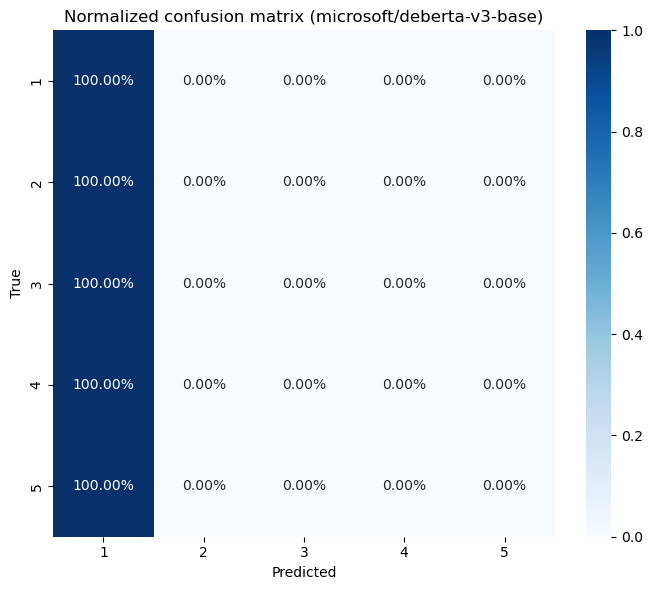

In [9]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
val_metrics, y_true, y_pred, val_probs = evaluate_val()
np.save(OUTPUT_DIR / "val_probs.npy", val_probs)        # keep for ensembling with other models
print(classification_report(y_true, y_pred, digits=4))

cm = confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4, 5])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Normalized confusion matrix ({MODEL_NAME})")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150); plt.show()


In [10]:
# micro-F1 = the competition metric (for single-label multi-class it equals accuracy)
print(f"micro-F1 (competition metric): {f1_score(y_true, y_pred, average='micro'):.4f}")

micro-F1 (competition metric): 0.2000


## 10. Test predictions
Next: run `Ensemble_Postprocess.ipynb` (blend models, tune decision rule).

In [11]:
test_probs = run_inference(test_df, desc="Predicting test")
np.save(OUTPUT_DIR / "test_probs.npy", test_probs)
out = test_df.copy()
out["predicted_overall"] = test_probs.argmax(1) + 1
out["expected_rating"] = np.round((test_probs * np.arange(1, 6)).sum(1), 4)
out.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print(out["predicted_overall"].value_counts().sort_index())


Predicting test:   0%|          | 0/625 [00:00<?, ?it/s]

predicted_overall
1    20000
Name: count, dtype: int64


## 11. Submission file
Required format: file name `q2_submission.csv`, a single column named `predicted`, **no index**, row *i* = prediction for test sample *i* (same order as `test_data.csv`).
The file is written to this model's output folder so the two notebooks never overwrite each other; copy the one you want to submit next to your report.

In [12]:
SUBMISSION_PATH = OUTPUT_DIR / "q2_submission.csv"
submission = pd.DataFrame({"predicted": test_probs.argmax(1) + 1})   # labels 1..5, original test order
submission.to_csv(SUBMISSION_PATH, index=False)                      # index=False -> no index column

# sanity checks
assert len(submission) == len(test_df)
assert submission["predicted"].between(1, 5).all()
try:
    n_raw = len(pd.read_csv("test_data.csv", usecols=["asin"], low_memory=False))
    assert n_raw == len(submission), f"row count mismatch: test_data.csv has {n_raw}, submission has {len(submission)}"
except FileNotFoundError:
    print("(test_data.csv not found next to the notebook - raw row-count check skipped)")

print("Saved:", SUBMISSION_PATH)
print(pd.read_csv(SUBMISSION_PATH).head())
print(submission["predicted"].value_counts().sort_index())

Saved: outputs_deberta-v3-base_summary_review\q2_submission.csv
   predicted
0          1
1          1
2          1
3          1
4          1
predicted
1    20000
Name: count, dtype: int64


## Experiment log (جدول آزمایش‌ها — مقادیر خالی را پس از هر اجرا پر کنید)

All numbers are accuracy on the held‑out validation set (30,000 rows). For single‑label multi‑class, accuracy = micro‑F1.

| # | Model | Input / preprocessing | Val acc (= micro‑F1) | Note |
|---|-------|-----------------------|----------------------|------|
| 1 | roberta-base | `summary_review`, head+tail, no stop‑word removal | 0.6966 | measured (epoch 5, best) |
| 2 | roberta-base | `full` (Brand \| Title \| Summary \| Review) | _fill_ | `DATA_TAG = ""` |
| 3 | roberta-base | `title_summary_review` | _fill_ | `DATA_TAG = "_title_summary_review"` |
| 4 | TF‑IDF + LR | all words kept | _from appendix_ | CPU baseline |
| 5 | TF‑IDF + LR | all sklearn stop words removed | _from appendix_ | CPU baseline |
| 6 | TF‑IDF + LR | stop words removed except negations/intensifiers | _from appendix_ | CPU baseline |
| 7 | **DeBERTa-v3-base** (this notebook) | `summary_review`, head+tail | _fill_ | |


## Appendix (optional, CPU only, a few minutes): evidence for the stop-word decision
A simple TF‑IDF + logistic‑regression classifier on the same pool/validation data, trained with and without stop‑word removal. It is not the final model; it is a cheap, reproducible check of the preprocessing choice explained at the top. Paste the three numbers into the experiment log (rows 4–6).

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression

n_per_class = min(12_000, int(pool_df["overall"].value_counts().min()))
sub = pool_df.groupby("overall", group_keys=False).sample(n=n_per_class, random_state=SEED)

def tfidf_val_acc(stop_words):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=300_000,
                          sublinear_tf=True, stop_words=stop_words)
    X_tr = vec.fit_transform(sub["model_input"])
    X_va = vec.transform(val_df["model_input"])
    clf = LogisticRegression(C=4.0, max_iter=300).fit(X_tr, sub["overall"])
    return accuracy_score(val_df["overall"], clf.predict(X_va))

SENTIMENT_STOP_WORDS = {"not", "no", "nor", "never", "cannot", "but", "very", "too",
                        "without", "nothing", "however"}
variants = {
    "keep all words": None,
    "remove ALL scikit-learn stop words": list(ENGLISH_STOP_WORDS),
    "remove stop words except negations/intensifiers": sorted(set(ENGLISH_STOP_WORDS) - SENTIMENT_STOP_WORDS),
}
for name, sw in variants.items():
    print(f"{name:50s} val acc = {tfidf_val_acc(sw):.4f}")

keep all words                                     val acc = 0.5579
remove ALL scikit-learn stop words                 val acc = 0.5206
remove stop words except negations/intensifiers    val acc = 0.5409
